<a href="https://colab.research.google.com/github/Bhavesh1412/CSL701-CS33_Machine-Learning-Lab/blob/main/Experiment_7_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student Name : Bhavesh Chandrakant Mundye

Batch :CS 02


Roll Number : CS33



Aim

To implement Principal Component Analysis (PCA) for dimensionality reduction on the Breast Cancer Wisconsin (Diagnostic) dataset, visualize the high-dimensional feature space in a reduced 2D plane, and evaluate its impact on classification performance.

## Objectives

1. To understand the concepts of dimensionality reduction, feature correlation, and Principal Component Analysis.

2. To preprocess, clean, and scale high-dimensional real-world data using StandardScaler.

3. To implement PCA using Python to compress feature dimensions from 30 continuous features down to 2 principal components.

4. To calculate and plot the explained variance ratio and cumulative explained variance.

5. To visualize the transformed 2D dataset and analyze class separability.

6. To evaluate and compare classification model performance (e.g., Logistic Regression) before and after applying PCA.

# Relevant Theory

### Support Vector Machine

Principal Component Analysis (PCA)Principal Component Analysis (PCA) is an unsupervised machine learning technique used for dimensionality reduction. It transforms a dataset containing a large set of correlated features into a smaller set of uncorrelated variables called Principal Components ($PCs$), while preserving as much data variance as possible.

Mathematical Steps:

1. Standardization: Scale each feature to have a mean of 0 ($\mu = 0$) and standard deviation of 1 ($\sigma = 1$).

2. Covariance Matrix: Compute the covariance matrix $C$ to quantify feature correlations:$$C = \frac{1}{n-1} X^T X$$

3. Eigen decomposition: Compute eigenvalues ($\lambda$) and eigenvectors ($v$) of matrix $C$:$$C v = \lambda v$$

    * Eigenvectors represent the direction of the principal axes.
    * Eigenvalues indicate the amount of variance along those axes.
4. Projection: Project original data $X$ onto top $k$ principal component directions $W$:$$X_{\text{pca}} = X \cdot W$$

###Dataset Information


1. Dataset Name: Breast Cancer Wisconsin (Diagnostic) Dataset

2. Kaggle Link: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

3. Classes: 2 binary classes (Malignant [$M$] and Benign [$B$])

4. Features: 30 continuous features computed from digitized images of fine needle aspirates (FNA) of a breast mass (e.g., radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, concavity_mean, etc.).

5. Non-Feature Columns: id (identifier) and Unnamed: 32 (empty column).

# Task 1: Import Libraries and Load Dataset

Import core Python libraries (numpy, pandas, matplotlib, seaborn, sklearn) and load data.csv obtained from Kaggle.

---

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tkinter import Tk, filedialog

root = Tk()
root.withdraw()

file_path = filedialog.askopenfilename(
    initialdir="D:/",
    filetypes=[("CSV files", "*.csv")]
)

df = pd.read_csv(file_path)

print(df.head())


Saving data.csv to data.csv
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_w

# Task 2: Explore the Dataset

Inspect missing values, view dataset summary statistics, check column data types, and inspect target class distributions (diagnosis).

Dataset shape: (569, 33)

First 5 rows:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst 

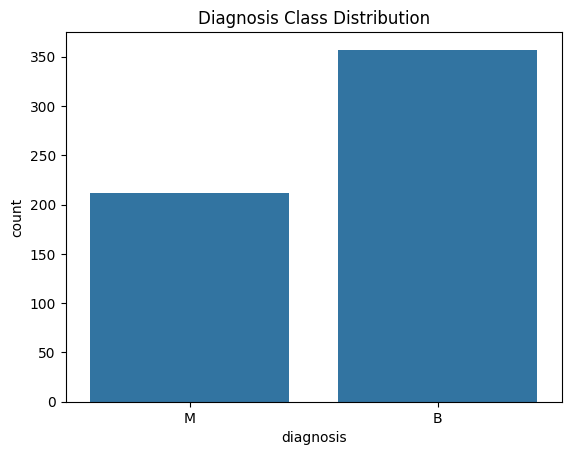

In [5]:
# Display dataset information
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
print(df.describe())

print("\nDiagnosis distribution:")
print(df["diagnosis"].value_counts())

# Plot class distribution
sns.countplot(data=df, x="diagnosis")
plt.title("Diagnosis Class Distribution")
plt.show()

# Task 3: Data Cleaning and Feature/Target Selection

Drop metadata columns (id and Unnamed: 32). Convert the categorical target column (diagnosis: 'M'/'B') into numerical values (1/0) and separate feature matrix $X$ (30 features) from label vector $y$.   

In [7]:
# Remove unnecessary columns if present
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Remove rows with missing values
df = df.dropna()

# Convert diagnosis into numerical values
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

# Separate features and target
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.head())

print("\nTarget values:")
print(y.value_counts())

Feature shape: (569, 30)
Target shape: (569,)

Features:
   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   fractal_dimension_mean  ...  rad

# Task 4: Standardize Features

Apply StandardScaler to transform all 30 numeric features so they have zero mean and unit variance ($\mu=0, \sigma=1$).

In [8]:
# Standardize all numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Standardized feature shape:", X_scaled.shape)

print("\nFirst 5 standardized rows:")
print(X_scaled[:5])

print("\nFeature means (approximately zero):")
print(np.round(X_scaled.mean(axis=0)[:5], 4))

Original feature shape: (569, 30)
Standardized feature shape: (569, 30)

First 5 standardized rows:
[[ 1.09706398e+00 -2.07333501e+00  1.26993369e+00  9.84374905e-01
   1.56846633e+00  3.28351467e+00  2.65287398e+00  2.53247522e+00
   2.21751501e+00  2.25574689e+00  2.48973393e+00 -5.65265059e-01
   2.83303087e+00  2.48757756e+00 -2.14001647e-01  1.31686157e+00
   7.24026158e-01  6.60819941e-01  1.14875667e+00  9.07083081e-01
   1.88668963e+00 -1.35929347e+00  2.30360062e+00  2.00123749e+00
   1.30768627e+00  2.61666502e+00  2.10952635e+00  2.29607613e+00
   2.75062224e+00  1.93701461e+00]
 [ 1.82982061e+00 -3.53632408e-01  1.68595471e+00  1.90870825e+00
  -8.26962447e-01 -4.87071673e-01 -2.38458552e-02  5.48144156e-01
   1.39236330e-03 -8.68652457e-01  4.99254601e-01 -8.76243603e-01
   2.63326966e-01  7.42401948e-01 -6.05350847e-01 -6.92926270e-01
  -4.40780058e-01  2.60162067e-01 -8.05450380e-01 -9.94437403e-02
   1.80592744e+00 -3.69203222e-01  1.53512599e+00  1.89048899e+00
  -3.75

# Task 5: Implement PCA (30D to 2D)

Use sklearn.decomposition.PCA to reduce feature dimensions from 30 down to 2 principal components ($PC_1$ and $PC_2$).

In [9]:
# Reduce 30 features to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original dimensions:", X_scaled.shape[1])
print("Reduced dimensions:", X_pca.shape[1])

print("\nFirst 5 PCA rows:")
print(X_pca[:5])

Original dimensions: 30
Reduced dimensions: 2

First 5 PCA rows:
[[ 9.19283683  1.94858307]
 [ 2.3878018  -3.76817174]
 [ 5.73389628 -1.0751738 ]
 [ 7.1229532  10.27558912]
 [ 3.93530207 -1.94807157]]


# Task 6: Analyze Explained Variance Ratio

Compute and print the variance explained by $PC_1$ and $PC_2$, along with the cumulative variance retained.


Variance explained by PC1: 44.27 %
Variance explained by PC2: 18.97 %
Cumulative variance retained: 63.24 %


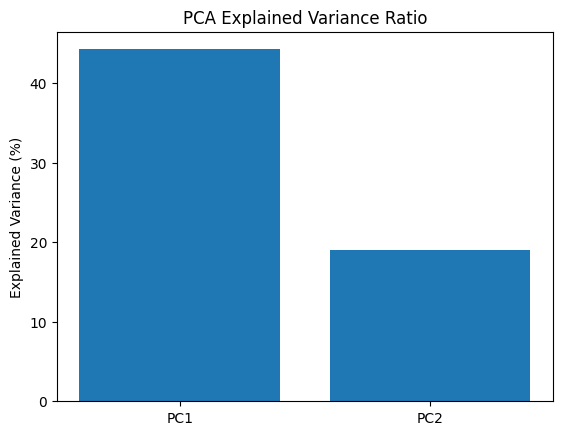

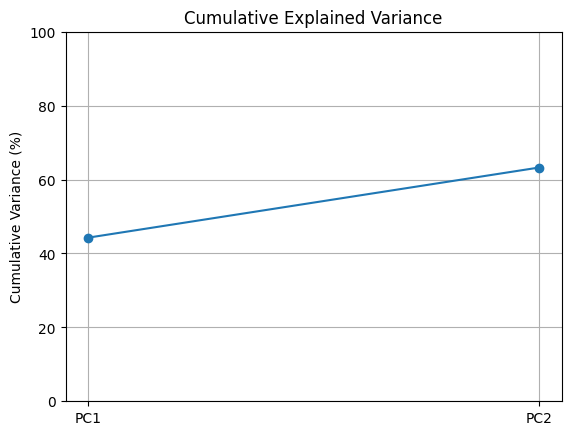

In [10]:
# Calculate explained variance
variance = pca.explained_variance_ratio_

print("Variance explained by PC1:", round(variance[0] * 100, 2), "%")
print("Variance explained by PC2:", round(variance[1] * 100, 2), "%")

print("Cumulative variance retained:",
      round(sum(variance) * 100, 2), "%")

# Plot explained variance
plt.bar(["PC1", "PC2"], variance * 100)
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance Ratio")
plt.show()

# Plot cumulative variance
plt.plot(["PC1", "PC2"], np.cumsum(variance) * 100, marker="o")
plt.ylabel("Cumulative Variance (%)")
plt.title("Cumulative Explained Variance")
plt.ylim(0, 100)
plt.grid(True)
plt.show()

# Task 7: Visualize PCA Transformed Boundary / Scatter Plot

Create a 2D scatter plot with $PC_1$ on the x-axis and $PC_2$ on the y-axis, hue-coded by tumor diagnosis (Malignant vs. Benign).

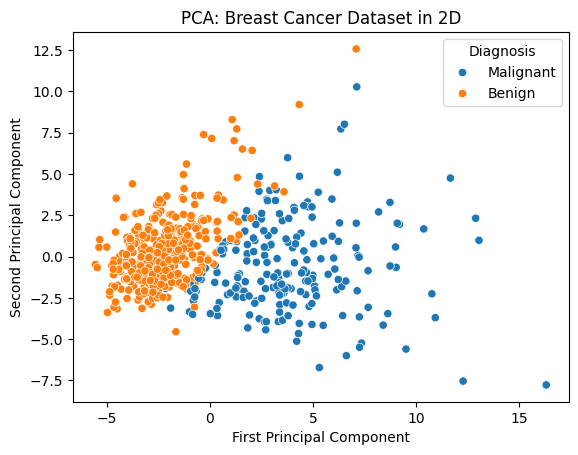

In [11]:
# Create a DataFrame for plotting
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Diagnosis"] = y.map({1: "Malignant", 0: "Benign"}).values

# Plot the two principal components
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Diagnosis"
)

plt.title("PCA: Breast Cancer Dataset in 2D")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.show()

# Task 8: Train Classifier on Raw High-Dimensional Data (30 Features)

Split the original scaled 30-feature dataset into training and testing sets. Train a Logistic Regression model and obtain baseline performance metrics.

In [12]:
# Split the standardized original features
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Logistic Regression
model_original = LogisticRegression(max_iter=1000)
model_original.fit(X_train, y_train)

# Predict test results
y_pred_original = model_original.predict(X_test)

# Display accuracy
print("Accuracy on original 30 features:",
      accuracy_score(y_test, y_pred_original))

Accuracy on original 30 features: 0.9649122807017544


# Task 9: Train Classifier on PCA Transformed Data (2 Features)

Split the 2-component PCA dataset into training and testing sets. Train a Logistic Regression model using only $PC_1$ and $PC_2$.

In [13]:
# Split the PCA-transformed features
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Logistic Regression on 2 components
model_pca = LogisticRegression(max_iter=1000)
model_pca.fit(X_train_pca, y_train_pca)

# Predict test results
y_pred_pca = model_pca.predict(X_test_pca)

# Display accuracy
print("Accuracy after PCA (2 features):",
      accuracy_score(y_test_pca, y_pred_pca))

Accuracy after PCA (2 features): 0.9385964912280702


# Task 10: Compare Classifier Performance

Compare the performance of the model before PCA (30 features) vs. after PCA (2 components) using:   

*   Accuracy Score
*   Confusion Matrix
*   Classification Report (Precision, Recall, F1-Score)  



Original Model Accuracy: 96.49 %
PCA Model Accuracy: 93.86 %

Confusion Matrix - Original 30 Features:
[[71  1]
 [ 3 39]]

Classification Report - Original 30 Features:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


Confusion Matrix - PCA 2 Features:
[[71  1]
 [ 6 36]]

Classification Report - PCA 2 Features:
              precision    recall  f1-score   support

      Benign       0.92      0.99      0.95        72
   Malignant       0.97      0.86      0.91        42

    accuracy                           0.94       114
   macro avg       0.95      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



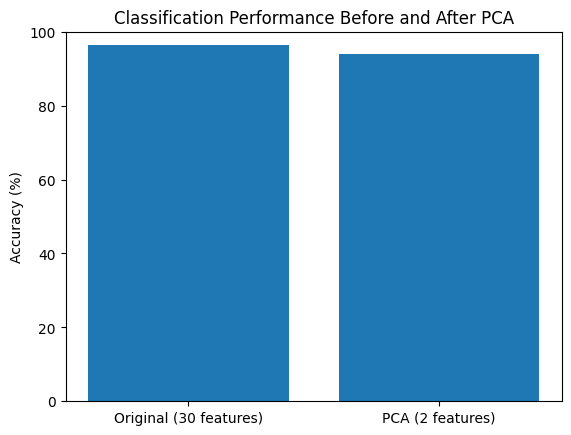

In [14]:
# Compare model accuracies
accuracy_original = accuracy_score(y_test, y_pred_original)
accuracy_pca = accuracy_score(y_test_pca, y_pred_pca)

print("Original Model Accuracy:", round(accuracy_original * 100, 2), "%")
print("PCA Model Accuracy:", round(accuracy_pca * 100, 2), "%")

# Confusion matrix for original model
print("\nConfusion Matrix - Original 30 Features:")
print(confusion_matrix(y_test, y_pred_original))

print("\nClassification Report - Original 30 Features:")
print(classification_report(
    y_test,
    y_pred_original,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

# Confusion matrix for PCA model
print("\nConfusion Matrix - PCA 2 Features:")
print(confusion_matrix(y_test_pca, y_pred_pca))

print("\nClassification Report - PCA 2 Features:")
print(classification_report(
    y_test_pca,
    y_pred_pca,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

# Accuracy comparison plot
plt.bar(
    ["Original (30 features)", "PCA (2 features)"],
    [accuracy_original * 100, accuracy_pca * 100]
)

plt.ylabel("Accuracy (%)")
plt.title("Classification Performance Before and After PCA")
plt.ylim(0, 100)
plt.show()

# Conclusion

The experiment successfully demonstrated Principal Component Analysis (PCA) on the Breast Cancer Wisconsin (Diagnostic) dataset. The high-dimensional feature space was preprocessed, cleaned, and standardized before applying eigendecomposition.

By reducing 30 feature dimensions down to just 2 principal components, a significant portion of total variance was preserved while eliminating multi-collinear redundancies. Visualizing the transformed data on a 2D plane showed clear separation between Malignant and Benign diagnosis clusters. Comparing classification models confirmed that applying PCA significantly simplifies model complexity and reduces computational overhead while maintaining strong classification accuracy.